In [1]:

import os, sys, torch

print("python :", sys.version.split()[0])
print("torch  :", torch.__version__)
print("cuda   :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu    :", torch.cuda.get_device_name(0))
else:
    print("!! GPU OFF hai -> Settings > Accelerator > GPU T4 x2 karo, phir restart")

# internet check (pretrained weights download ke liye chahiye)
import socket
try:
    socket.create_connection(("pypi.org", 443), timeout=5)
    print("internet: ON")
except Exception:
    print("!! internet OFF hai -> Settings > Internet > ON karo, phir restart")

# dataset root dhundo
ROOT = None
for dirpath, dirnames, _ in os.walk("/kaggle/input"):
    if any(d.lower().startswith("cam_") for d in dirnames):
        ROOT = dirpath
        break
assert ROOT, "Cam_* chunk folders nahi mile -> dataset cam_12_chunk_0-12 attach karo"
print("ROOT   :", ROOT)

WORK = "/kaggle/working/reid"
os.makedirs(WORK, exist_ok=True)
print("WORK   :", WORK)

python : 3.12.13
torch  : 2.10.0+cu128
cuda   : True
gpu    : Tesla T4
internet: ON
ROOT   : /kaggle/input/datasets/payal1238gupta/cam-12-chunk-0-12
WORK   : /kaggle/working/reid


In [2]:
# ===== CELL 1: data scan + identity-level split =====
import os, random, json
from glob import glob
from PIL import Image

random.seed(42)

chunks = sorted(d for d in os.listdir(ROOT) if d.lower().startswith("cam_"))
print("chunks:", len(chunks))

ids = {}                       # "chunk/track_id" -> [jpg paths]
for ch in chunks:
    for tid in os.listdir(os.path.join(ROOT, ch)):
        p = os.path.join(ROOT, ch, tid)
        if not os.path.isdir(p):
            continue
        imgs = sorted(glob(os.path.join(p, "*.jpg")))
        if imgs:
            ids[f"{ch}/{tid}"] = imgs

print(f"identities: {len(ids)} | images: {sum(len(v) for v in ids.values())}")

cnt = sorted(len(v) for v in ids.values())
print("images/id  min:", cnt[0], "median:", cnt[len(cnt)//2], "max:", cnt[-1])

MIN_IMG = 5                    # triplet ke liye kam se kam 2 chahiye, 5 safe hai
ids = {k: v for k, v in ids.items() if len(v) >= MIN_IMG}
print(f"after MIN_IMG={MIN_IMG}: identities: {len(ids)} | images: {sum(len(v) for v in ids.values())}")

sz = [Image.open(v[0]).size for v in list(ids.values())[:200]]
print("mean crop (w,h):", round(sum(s[0] for s in sz)/len(sz)), round(sum(s[1] for s in sz)/len(sz)))

# identity-level split: 80% ids train, 20% ids held-out eval
keys = sorted(ids)
random.shuffle(keys)
n_eval = int(0.2 * len(keys))
eval_ids, train_ids = keys[:n_eval], keys[n_eval:]

# held-out ids -> query (1 img/id) + gallery (baaki saari)
query, gallery = [], []
for k in eval_ids:
    imgs = ids[k][:]
    random.shuffle(imgs)
    query.append((imgs[0], k))
    gallery += [(im, k) for im in imgs[1:]]

split = {"train": {k: ids[k] for k in train_ids}, "query": query, "gallery": gallery}
json.dump(split, open(f"{WORK}/split.json", "w"))

print(f"train ids: {len(train_ids)} ({sum(len(ids[k]) for k in train_ids)} imgs)")
print(f"eval  ids: {len(eval_ids)} | query: {len(query)} | gallery: {len(gallery)}")

# sanity: train aur eval identities overlap nahi karni chahiye
assert not (set(train_ids) & set(eval_ids)), "LEAK! train/eval ids overlap"
print("leak check: OK")

chunks: 15
identities: 302 | images: 27042
images/id  min: 2 median: 50 max: 1577
after MIN_IMG=5: identities: 294 | images: 27015
mean crop (w,h): 200 337
train ids: 236 (22033 imgs)
eval  ids: 58 | query: 58 | gallery: 4924
leak check: OK


## Cell 2 — dataset + transforms

Do cheezein yahan fix hui hain:
- `__len__` ab **images-scale** pe hai (`identities x SAMPLES_PER_ID`), identities pe nahi — warna
  ek epoch mein sirf 7 batches banti thi
- anchor aur positive **alag images** hain (`random.sample(imgs, 2)`)

`ColorJitter` + `RandomGrayscale` jaanbujh ke rakhe hain taaki model kapdon ke rang pe kam depend kare.

In [3]:
# ===== CELL 2: dataset + transforms =====
import json, random
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

split      = json.load(open(f"{WORK}/split.json"))
train_map  = split["train"]                            # {"chunk/track_id": [paths]}
train_keys = sorted(train_map)
key2label  = {k: i for i, k in enumerate(train_keys)}  # CE loss ke liye
NUM_CLASSES = len(train_keys)

H, W = 256, 128                 # Re-ID standard (tall crop, padding waste nahi)
SAMPLES_PER_ID = 8              # har identity se ~8 triplets per epoch

train_tf = transforms.Compose([
    transforms.Resize((H, W)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.03),
    transforms.RandomGrayscale(p=0.1),
    transforms.Pad(10),
    transforms.RandomCrop((H, W)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.2), value=0),
])

eval_tf = transforms.Compose([
    transforms.Resize((H, W)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


class TripletReID(Dataset):
    """har item = (anchor, positive, negative, anchor_label)"""
    def __init__(self, id_map, transform, samples_per_id=SAMPLES_PER_ID):
        self.id_map = id_map
        self.keys   = sorted(id_map)
        self.tf     = transform
        self.spi    = samples_per_id

    def __len__(self):
        return len(self.keys) * self.spi

    def _load(self, path):
        return self.tf(Image.open(path).convert("RGB"))

    def __getitem__(self, idx):
        a_key = self.keys[idx % len(self.keys)]
        imgs  = self.id_map[a_key]
        a_path, p_path = random.sample(imgs, 2)      # anchor != positive
        n_key = a_key
        while n_key == a_key:
            n_key = random.choice(self.keys)
        n_path = random.choice(self.id_map[n_key])
        return (self._load(a_path), self._load(p_path), self._load(n_path), key2label[a_key])


class EvalSet(Dataset):
    """query / gallery ke liye: (image, identity_key)"""
    def __init__(self, pairs, transform):
        self.pairs = pairs
        self.tf = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        path, key = self.pairs[idx]
        return self.tf(Image.open(path).convert("RGB")), key


BATCH = 32
train_ds   = TripletReID(train_map, train_tf)
query_ds   = EvalSet(split["query"],   eval_tf)
gallery_ds = EvalSet(split["gallery"], eval_tf)

train_dl   = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                        num_workers=2, drop_last=True, pin_memory=True)
query_dl   = DataLoader(query_ds,   batch_size=64, num_workers=2)
gallery_dl = DataLoader(gallery_ds, batch_size=64, num_workers=2)

print("train identities :", NUM_CLASSES)
print("train samples    :", len(train_ds))
print("batches/epoch    :", len(train_dl))
print("query / gallery  :", len(query_ds), "/", len(gallery_ds))

a, p, n, lbl = train_ds[0]
print("tensor shape     :", tuple(a.shape), "| label:", lbl)

train identities : 236
train samples    : 1888
batches/epoch    : 59
query / gallery  : 58 / 4924
tensor shape     : (3, 256, 128) | label: 0


In [4]:
# ===== CELL 3: OSNet backend — torchreid -> boxmot -> resnet50 =====
BACKEND = None

# raasta 1: torchreid
try:
    import torchreid
    BACKEND = "osnet"
    print("torchreid pehle se maujood")
except Exception:
    print("torchreid install ho raha hai... (2-4 min)")
    !pip install -q gdown yacs
    !pip install -q --no-deps git+https://github.com/KaiyangZhou/deep-person-reid.git
    try:
        import torchreid
        BACKEND = "osnet"
        print("torchreid OK")
    except Exception as e:
        print("torchreid FAIL ->", type(e).__name__, e)

# raasta 2: boxmot (isme bhi wahi OSNet architecture hai, aur ye aapke env mein pehle chal chuka hai)
if BACKEND is None:
    try:
        from boxmot.appearance.backbones.osnet import osnet_x1_0
        BACKEND = "osnet_boxmot"
        print("boxmot osnet OK")
    except Exception:
        print("boxmot install ho raha hai... (3-5 min)")
        !pip install -q boxmot
        try:
            from boxmot.appearance.backbones.osnet import osnet_x1_0
            BACKEND = "osnet_boxmot"
            print("boxmot osnet OK")
        except Exception as e:
            print("boxmot FAIL ->", type(e).__name__, e)

# raasta 3: guaranteed fallback
if BACKEND is None:
    BACKEND = "resnet50"
    print("dono fail -> torchvision resnet50 use hoga")

print("\nBACKEND =", BACKEND)

torchreid install ho raha hai... (2-4 min)
  Preparing metadata (setup.py) ... done
torchreid OK

BACKEND = osnet


In [5]:
# ===== CELL 4: model =====
import torch, torch.nn as nn, torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


class ReIDNet(nn.Module):
    def __init__(self, num_classes, backend="osnet"):
        super().__init__()
        self.backend = backend
        if backend == "osnet":
            import torchreid
            self.net = torchreid.models.build_model(
                name="osnet_x1_0", num_classes=num_classes,
                loss="triplet", pretrained=True)
        elif backend == "osnet_boxmot":
            from boxmot.appearance.backbones.osnet import osnet_x1_0
            self.net = osnet_x1_0(num_classes=num_classes, pretrained=True, loss="triplet")
        else:
            from torchvision import models
            m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
            m.layer4[0].downsample[0].stride = (1, 1)   # last-stride=1: Re-ID trick
            m.layer4[0].conv2.stride = (1, 1)
            self.backbone   = nn.Sequential(*list(m.children())[:-2])
            self.pool       = nn.AdaptiveAvgPool2d(1)
            self.bnneck     = nn.BatchNorm1d(2048)
            self.bnneck.bias.requires_grad_(False)
            self.classifier = nn.Linear(2048, num_classes, bias=False)

    def forward(self, x):
        if self.backend in ("osnet", "osnet_boxmot"):
            out = self.net(x)
            if self.training:
                logits, feat = out
                return logits, feat           # triplet raw feat pe
            return F.normalize(out, dim=1)    # eval: normalized embedding
        f  = self.pool(self.backbone(x)).flatten(1)
        fb = self.bnneck(f)
        if self.training:
            return self.classifier(fb), f
        return F.normalize(fb, dim=1)


model = ReIDNet(NUM_CLASSES, BACKEND).to(device)
print(f"params: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")

device: cuda


Downloading...
From: https://drive.google.com/uc?id=1LaG1EJpHrxdAxKnSCJ_i0u-nbxSAeiFY
To: /root/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth
100%|██████████| 10.9M/10.9M [00:00<00:00, 164MB/s]


Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
params: 2.29M


In [6]:
# ===== CELL 5: smoke test =====
a, p, n, lbl = next(iter(train_dl))
print("batch:", tuple(a.shape), "| labels:", tuple(lbl.shape))

model.train()
logits, feat = model(a.to(device))
print("logits :", tuple(logits.shape), "  (batch x", NUM_CLASSES, "hona chahiye)")
print("feat   :", tuple(feat.shape))

model.eval()
with torch.no_grad():
    e = model(a[:4].to(device))
print("eval embedding:", tuple(e.shape), "| norm:", round(e[0].norm().item(), 4), "(1.0 hona chahiye)")

batch: (32, 3, 256, 128) | labels: (32,)
logits : (32, 236)   (batch x 236 hona chahiye)
feat   : (32, 512)
eval embedding: (4, 512) | norm: 1.0 (1.0 hona chahiye)


In [7]:
# ===== CELL 6: loss + optimizer + eval function =====
import numpy as np, time

EPOCHS   = 40
LR       = 3e-4
MARGIN   = 0.3
WARMUP   = 5

ce_loss  = nn.CrossEntropyLoss(label_smoothing=0.1)
tri_loss = nn.TripletMarginLoss(margin=MARGIN, p=2)

optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=5e-4)

def lr_at(epoch):
    if epoch < WARMUP:
        return (epoch + 1) / WARMUP
    prog = (epoch - WARMUP) / max(1, EPOCHS - WARMUP)
    return 0.5 * (1 + np.cos(np.pi * prog))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_at)
scaler    = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())


@torch.no_grad()
def extract(loader):
    model.eval()
    feats, keys = [], []
    for imgs, ks in loader:
        f = model(imgs.to(device, non_blocking=True))
        feats.append(f.float().cpu())
        keys += list(ks)
    return torch.cat(feats), np.array(keys)


def evaluate(verbose=False):
    qf, qk = extract(query_dl)
    gf, gk = extract(gallery_dl)
    sim = (qf @ gf.t()).numpy()          # features normalized -> cosine similarity

    cmcs, aps = [], []
    for i in range(sim.shape[0]):
        order   = np.argsort(-sim[i])
        matches = (gk[order] == qk[i]).astype(np.int32)
        if matches.sum() == 0:
            continue
        cmc = matches.cumsum().clip(max=1)
        cmcs.append(cmc)
        pos  = np.where(matches == 1)[0]
        prec = [(j + 1) / (rank + 1) for j, rank in enumerate(pos)]
        aps.append(float(np.mean(prec)))

    cmc = np.mean(cmcs, axis=0)
    res = {"Rank-1": float(cmc[0]), "Rank-5": float(cmc[4]),
           "Rank-10": float(cmc[9]), "mAP": float(np.mean(aps))}
    if verbose:
        print("  " + " | ".join(f"{k} {v*100:5.2f}%" for k, v in res.items()))
    return res


print("training se pehle (sirf pretrained weights, koi fine-tuning nahi):")
base = evaluate(verbose=True)

training se pehle (sirf pretrained weights, koi fine-tuning nahi):
  Rank-1 100.00% | Rank-5 100.00% | Rank-10 100.00% | mAP 35.91%


In [8]:
# ===== CELL 7: training =====
best_map, history = -1.0, []
t0 = time.time()

for epoch in range(EPOCHS):
    model.train()
    tot, tot_ce, tot_tri, nb = 0.0, 0.0, 0.0, 0

    for a, p, n, lbl in train_dl:
        a, p, n, lbl = (a.to(device, non_blocking=True), p.to(device, non_blocking=True),
                        n.to(device, non_blocking=True), lbl.to(device, non_blocking=True))
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            logits_a, fa = model(a)
            _,        fp = model(p)
            _,        fn = model(n)
            l_ce  = ce_loss(logits_a, lbl)
            l_tri = tri_loss(F.normalize(fa, dim=1),
                             F.normalize(fp, dim=1),
                             F.normalize(fn, dim=1))
            loss = l_ce + l_tri

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        tot += loss.item(); tot_ce += l_ce.item(); tot_tri += l_tri.item(); nb += 1

    scheduler.step()
    msg = (f"epoch {epoch+1:3d}/{EPOCHS} | loss {tot/nb:.4f} "
           f"(ce {tot_ce/nb:.4f} tri {tot_tri/nb:.4f}) | lr {scheduler.get_last_lr()[0]:.2e}")

    if (epoch + 1) % 2 == 0 or epoch == EPOCHS - 1:
        res = evaluate()
        history.append({"epoch": epoch + 1, **res})
        msg += f" | R1 {res['Rank-1']*100:5.2f}% mAP {res['mAP']*100:5.2f}%"
        if res["mAP"] > best_map:
            best_map = res["mAP"]
            torch.save({"state_dict": model.state_dict(), "backend": BACKEND,
                        "num_classes": NUM_CLASSES, "epoch": epoch + 1, "metrics": res},
                       f"{WORK}/reid_best.pt")
            msg += "  <- best, saved"
    print(msg)

print(f"\ntraining done in {(time.time()-t0)/60:.1f} min | best mAP: {best_map*100:.2f}%")

epoch   1/40 | loss 5.6859 (ce 5.4611 tri 0.2248) | lr 1.20e-04
epoch   2/40 | loss 5.4585 (ce 5.2662 tri 0.1922) | lr 1.80e-04 | R1 100.00% mAP 41.33%  <- best, saved
epoch   3/40 | loss 5.0409 (ce 4.9087 tri 0.1322) | lr 2.40e-04
epoch   4/40 | loss 4.4911 (ce 4.3953 tri 0.0958) | lr 3.00e-04 | R1 100.00% mAP 52.13%  <- best, saved
epoch   5/40 | loss 3.8537 (ce 3.7881 tri 0.0656) | lr 3.00e-04
epoch   6/40 | loss 3.3049 (ce 3.2516 tri 0.0533) | lr 2.99e-04 | R1 100.00% mAP 60.33%  <- best, saved
epoch   7/40 | loss 2.8284 (ce 2.7818 tri 0.0466) | lr 2.98e-04
epoch   8/40 | loss 2.4536 (ce 2.4195 tri 0.0341) | lr 2.95e-04 | R1 100.00% mAP 66.72%  <- best, saved
epoch   9/40 | loss 2.1248 (ce 2.0942 tri 0.0306) | lr 2.90e-04
epoch  10/40 | loss 1.8882 (ce 1.8604 tri 0.0278) | lr 2.85e-04 | R1 100.00% mAP 68.07%  <- best, saved
epoch  11/40 | loss 1.7153 (ce 1.6904 tri 0.0249) | lr 2.79e-04
epoch  12/40 | loss 1.6048 (ce 1.5825 tri 0.0223) | lr 2.71e-04 | R1 100.00% mAP 71.01%  <- best

In [9]:
# ===== CELL 8: final comparison =====
import json

ckpt = torch.load(f"{WORK}/reid_best.pt", map_location=device, weights_only=False)
model.load_state_dict(ckpt["state_dict"])
final = evaluate()

print(f"backend: {BACKEND} | best epoch: {ckpt['epoch']}")
print(f"{'metric':8} {'pretrained':>12} {'trained':>12} {'delta':>10}")
for k in ["Rank-1", "Rank-5", "Rank-10", "mAP"]:
    d = (final[k] - base[k]) * 100
    print(f"{k:8} {base[k]*100:11.2f}% {final[k]*100:11.2f}% {d:+9.2f}")

json.dump({"backend": BACKEND, "epochs": EPOCHS, "train_ids": NUM_CLASSES,
           "eval_ids": len(split["query"]), "gallery": len(split["gallery"]),
           "pretrained": base, "trained": final, "history": history},
          open(f"{WORK}/reid_results.json", "w"), indent=2)
print("\nsaved:", f"{WORK}/reid_results.json", "|", f"{WORK}/reid_best.pt")

backend: osnet | best epoch: 20
metric     pretrained      trained      delta
Rank-1        100.00%      100.00%     +0.00
Rank-5        100.00%      100.00%     +0.00
Rank-10       100.00%      100.00%     +0.00
mAP            35.91%       74.57%    +38.66

saved: /kaggle/working/reid/reid_results.json | /kaggle/working/reid/reid_best.pt


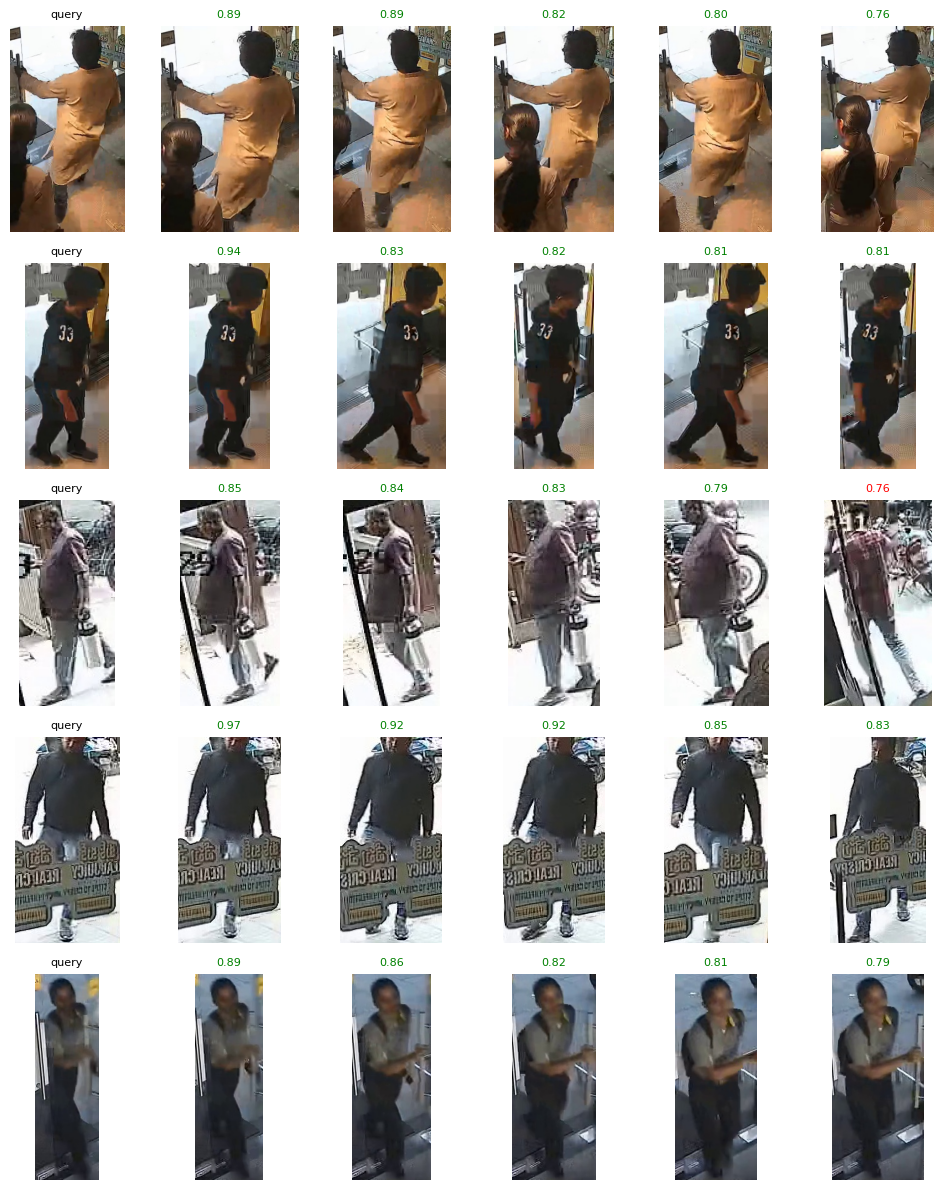

In [10]:
# ===== CELL 9: top-5 retrieval visualization =====
import matplotlib.pyplot as plt
from PIL import Image

qf, qk = extract(query_dl)
gf, gk = extract(gallery_dl)
sim = (qf @ gf.t()).numpy()

N_SHOW = 5
fig, axes = plt.subplots(N_SHOW, 6, figsize=(10, 2.4 * N_SHOW))
for r in range(N_SHOW):
    qi = r * (len(qk) // N_SHOW)
    axes[r, 0].imshow(Image.open(split["query"][qi][0]).convert("RGB"))
    axes[r, 0].set_title("query", fontsize=8)
    axes[r, 0].axis("off")
    for c, gi in enumerate(np.argsort(-sim[qi])[:5]):
        ok = gk[gi] == qk[qi]
        axes[r, c+1].imshow(Image.open(split["gallery"][gi][0]).convert("RGB"))
        axes[r, c+1].set_title(f"{sim[qi][gi]:.2f}", fontsize=8,
                               color="green" if ok else "red")
        axes[r, c+1].axis("off")
        for s in axes[r, c+1].spines.values():
            s.set_edgecolor("green" if ok else "red")
plt.tight_layout()
plt.savefig(f"{WORK}/retrieval_examples.png", dpi=110)
plt.show()

In [11]:
# ===== CELL 10: BoxMOT-compatible export =====
if BACKEND == "osnet":
    ckpt = torch.load(f"{WORK}/reid_best.pt", map_location="cpu", weights_only=False)
    sd = {k.replace("net.", "", 1): v for k, v in ckpt["state_dict"].items() if k.startswith("net.")}
    torch.save({"state_dict": sd}, f"{WORK}/osnet_x1_0_cam12.pt")
    print("exported ->", f"{WORK}/osnet_x1_0_cam12.pt")
    print("keys:", len(sd), "| agle notebook mein: reid_weights=Path('.../osnet_x1_0_cam12.pt')")
else:
    print("BACKEND =", BACKEND, "-> BoxMOT export skip; custom embedder wrapper chahiye hoga")

exported -> /kaggle/working/reid/osnet_x1_0_cam12.pt
keys: 567 | agle notebook mein: reid_weights=Path('.../osnet_x1_0_cam12.pt')
